# BÀI THỰC HÀNH LAB 3: DỰ BÁO CHUỖI THỜI GIAN VỚI MÔ HÌNH MACHINE LEARNING (XGBOOST, RANDOM FOREST & LINEAR REGRESSION)
---
**Học phần:** Xử lý và Phân tích Chuỗi thời gian (Time Series Analysis)  
**Bộ dữ liệu:** PJM Hourly Energy Consumption - American Electric Power (`AEP_hourly.csv`)  
**Mục tiêu bài thực hành:**
1. Khảo sát dữ liệu chuỗi thời gian phụ tải điện năng (Hourly Energy Consumption).
2. Xử lý làm sạch chuỗi (trùng lặp mốc giờ do DST, thiếu mốc giờ) và phân tích thăm dò EDA (xu hướng, tính mùa vụ chu kỳ 24h và chu kỳ tuần).
3. Trích xuất đặc trưng chuyên sâu cho chuỗi thời gian dạng Tabular (Lag features, Rolling statistics, Calendar features).
4. Phân chia Train/Test theo trình tự thời gian nghiêm ngặt (tránh Data Leakage / Look-ahead bias).
5. Huấn luyện và so chuẩn (Benchmark) 3 mô hình học máy: **Linear Regression**, **Random Forest**, **XGBoost Regressor**.
6. Đánh giá chi tiết bằng các độ đo định lượng (**MAE, RMSE, MAPE**) và trực quan hóa Feature Importance.
7. Triển khai phương pháp dự báo đa bước lặp lại (**Recursive Multi-step Forecasting**) 24 giờ tiếp theo.
8. Trả lời chi tiết 3 câu hỏi vấn đáp lý thuyết & thực tiễn trọng tâm.


## 1. Thiết lập môi trường & Import thư viện

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error
import warnings

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 11

print("Đã tải thành công các thư viện cần thiết!")


Đã tải thành công các thư viện cần thiết!


## 2. Tải và Khảo sát Dữ liệu Ban đầu (Data Ingestion & Inspection)
Chúng ta sử dụng tập dữ liệu phụ tải điện của công ty năng lượng **American Electric Power (AEP)** thuộc lưới điện PJM Interconnection từ năm 2004 đến 2018 (đơn vị: Megawatts - MW).

In [2]:
data_path = '../data/raw/AEP_hourly.csv'
df_raw = pd.read_csv(data_path)

print(f"Kích thước dữ liệu gốc: {df_raw.shape[0]:,} dòng, {df_raw.shape[1]} cột")
print("\n5 dòng đầu tiên:")
display(df_raw.head())
print("\nThông tin kiểu dữ liệu và giá trị thiếu:")
print(df_raw.info())


Kích thước dữ liệu gốc: 121,273 dòng, 2 cột

5 dòng đầu tiên:


,Datetime,AEP_MW
0,2004-12-31 01:00:00,13478.0
1,2004-12-31 02:00:00,12865.0
2,2004-12-31 03:00:00,12577.0
3,2004-12-31 04:00:00,12517.0
4,2004-12-31 05:00:00,12670.0



Thông tin kiểu dữ liệu và giá trị thiếu:
<class 'pandas.DataFrame'>
RangeIndex: 121273 entries, 0 to 121272
Data columns (total 2 columns):
 #   Column    Non-Null Count   Dtype  
---  ------    --------------   -----  
 0   Datetime  121273 non-null  str    
 1   AEP_MW    121273 non-null  float64
dtypes: float64(1), str(1)
memory usage: 1.9 MB
None


## 3. Tiền xử lý Dữ liệu: Xử lý Datetime Index, Bù khuyết và Chuẩn hóa Tần số
Trong các tập dữ liệu chuỗi thời gian thực tế, hiện tượng đổi giờ mùa hè (Daylight Saving Time - DST) thường gây ra:
- **Trùng lặp timestamp** vào mùa thu (khi đồng hồ lùi lại 1 tiếng).
- **Thiếu timestamp** vào mùa xuân (khi đồng hồ nhảy cóc 1 tiếng).
Ta cần sắp xếp, loại bỏ trùng lặp và đồng bộ hóa tần số cố định `1h` (`asfreq('h')`) kèm phép nội suy tuyến tính `interpolate(method='time')`.

In [3]:
# Chuyển đổi Datetime và đặt làm index
df = df_raw.copy()
df['Datetime'] = pd.to_datetime(df['Datetime'])
df = df.sort_values('Datetime').reset_index(drop=True)

# Kiểm tra trùng lặp Datetime
duplicate_count = df['Datetime'].duplicated().sum()
print(f"Số lượng mốc giờ bị trùng lặp: {duplicate_count}")

# Xóa trùng lặp (giữ bản ghi đầu tiên)
df = df.drop_duplicates(subset=['Datetime']).set_index('Datetime')

# Ép tần số theo giờ cố định ('h')
df = df.asfreq('h')

missing_count = df['AEP_MW'].isna().sum()
print(f"Số lượng mốc giờ bị khuyết sau khi chuẩn hóa tần số 'h': {missing_count} ({(missing_count/len(df))*100:.3f}%)")

# Nội suy tuyến tính cho các mốc giờ khuyết
df['AEP_MW'] = df['AEP_MW'].interpolate(method='time')

print(f"Khoảng thời gian khảo sát: {df.index.min()} -> {df.index.max()}")
print(f"Tổng số quan sát liên tục 1 giờ: {len(df):,} mốc")


Số lượng mốc giờ bị trùng lặp: 4
Số lượng mốc giờ bị khuyết sau khi chuẩn hóa tần số 'h': 27 (0.022%)
Khoảng thời gian khảo sát: 2004-10-01 01:00:00 -> 2018-08-03 00:00:00
Tổng số quan sát liên tục 1 giờ: 121,296 mốc


## 4. Phân tích Thăm dò Dữ liệu (Exploratory Data Analysis - EDA)
Ta quan sát toàn cảnh chuỗi thời gian và chu kỳ tiêu thụ phụ tải điện năng trong 24 giờ của một ngày.

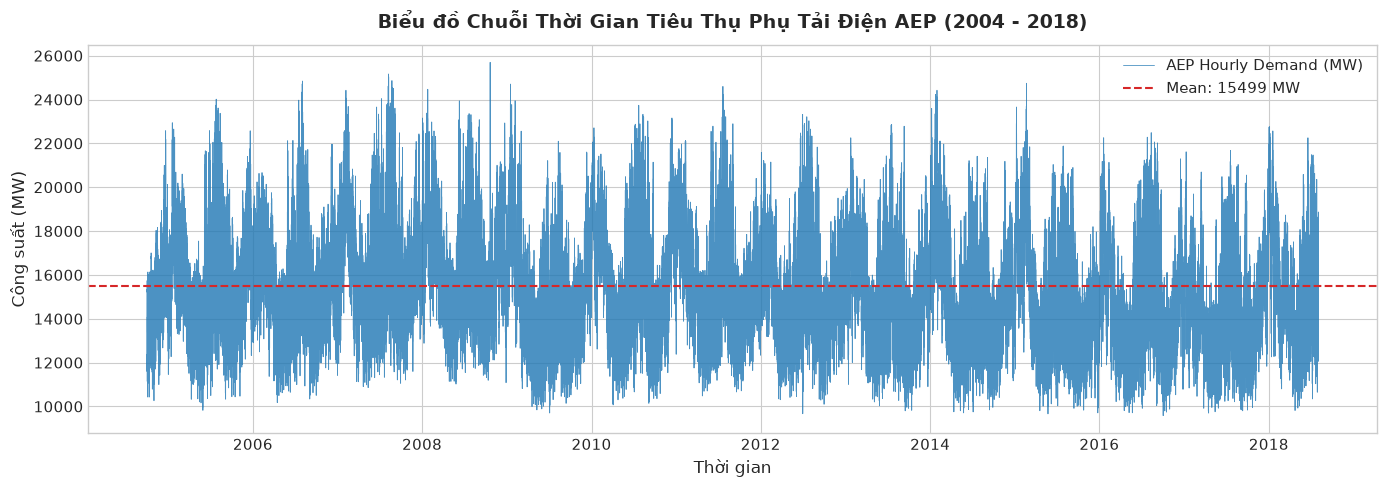

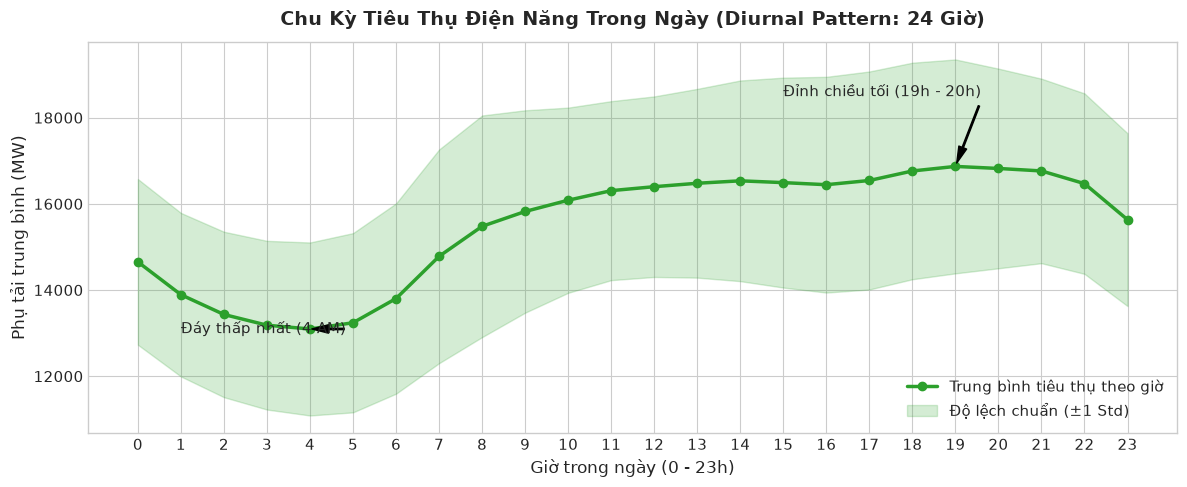

In [4]:
# Trực quan hóa toàn bộ chuỗi phụ tải điện
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df.index, df['AEP_MW'], color='#1f77b4', lw=0.6, alpha=0.8, label='AEP Hourly Demand (MW)')
ax.axhline(df['AEP_MW'].mean(), color='#d62728', linestyle='--', lw=1.5, label=f'Mean: {df["AEP_MW"].mean():.0f} MW')
ax.set_title('Biểu đồ Chuỗi Thời Gian Tiêu Thụ Phụ Tải Điện AEP (2004 - 2018)', fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('Thời gian', fontsize=12)
ax.set_ylabel('Công suất (MW)', fontsize=12)
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

# Trực quan hóa chu kỳ 24 giờ
df_eda = df.copy()
df_eda['hour'] = df_eda.index.hour
hourly_stats = df_eda.groupby('hour')['AEP_MW'].agg(['mean', 'std'])

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(hourly_stats.index, hourly_stats['mean'], marker='o', color='#2ca02c', lw=2.5, label='Trung bình tiêu thụ theo giờ')
ax.fill_between(hourly_stats.index, hourly_stats['mean'] - hourly_stats['std'], hourly_stats['mean'] + hourly_stats['std'], 
                alpha=0.2, color='#2ca02c', label='Độ lệch chuẩn (±1 Std)')
ax.set_title('Chu Kỳ Tiêu Thụ Điện Năng Trong Ngày (Diurnal Pattern: 24 Giờ)', fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('Giờ trong ngày (0 - 23h)', fontsize=12)
ax.set_ylabel('Phụ tải trung bình (MW)', fontsize=12)
ax.set_xticks(range(0, 24))
ax.annotate('Đáy thấp nhất (4 AM)', xy=(4, hourly_stats.loc[4, 'mean']), xytext=(1, 13000),
            arrowprops=dict(facecolor='black', shrink=0.05, width=1, headwidth=6))
ax.annotate('Đỉnh chiều tối (19h - 20h)', xy=(19, hourly_stats.loc[19, 'mean']), xytext=(15, 18500),
            arrowprops=dict(facecolor='black', shrink=0.05, width=1, headwidth=6))
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()


## 5. Kỹ nghệ Đặc trưng (Feature Engineering for Tabular ML)
Để chuyển đổi bài toán chuỗi thời gian thành học có giám sát (Supervised Learning), ta tạo 3 nhóm đặc trưng:
1. **Đặc trưng độ trễ (Lag Features):** $t-1, t-2, t-3$ (quán tính ngắn hạn), $t-24, t-48$ (chu kỳ ngày), $t-168$ (chu kỳ 1 tuần = $7 \times 24$h).
2. **Đặc trưng thống kê trượt (Rolling Statistics):** Trung bình và độ lệch chuẩn trượt 24 giờ và 168 giờ (lưu ý tính toán trên `shift(1)` để tránh rò rỉ giá trị hiện tại $t$).
3. **Đặc trưng lịch (Calendar Features):** `hour`, `dayofweek`, `quarter`, `month`, `year`, `dayofyear`, `is_weekend`.

In [5]:
df_feat = df.copy()

# 1. Lag features
for lag in [1, 2, 3, 24, 48, 168]:
    df_feat[f'lag_{lag}'] = df_feat['AEP_MW'].shift(lag)

# 2. Rolling statistics (dùng shift(1) để ngăn rò rỉ thông tin của điểm hiện tại)
shifted_series = df_feat['AEP_MW'].shift(1)
df_feat['rolling_mean_24h'] = shifted_series.rolling(window=24).mean()
df_feat['rolling_std_24h'] = shifted_series.rolling(window=24).std()
df_feat['rolling_mean_168h'] = shifted_series.rolling(window=168).mean()
df_feat['rolling_std_168h'] = shifted_series.rolling(window=168).std()

# 3. Calendar features
df_feat['hour'] = df_feat.index.hour
df_feat['dayofweek'] = df_feat.index.dayofweek
df_feat['quarter'] = df_feat.index.quarter
df_feat['month'] = df_feat.index.month
df_feat['year'] = df_feat.index.year
df_feat['dayofyear'] = df_feat.index.dayofyear
df_feat['is_weekend'] = (df_feat['dayofweek'] >= 5).astype(int)

# Bỏ các dòng NaN ở đầu chuỗi do trượt cửa sổ 168h
df_feat = df_feat.dropna()
print(f"Kích thước ma trận đặc trưng sau khi loại bỏ NaN: {df_feat.shape}")
display(df_feat.head(3))


Kích thước ma trận đặc trưng sau khi loại bỏ NaN: (121128, 18)


,AEP_MW,lag_1,lag_2,lag_3,lag_24,lag_48,lag_168,rolling_mean_24h,rolling_std_24h,rolling_mean_168h,rolling_std_168h,hour,dayofweek,quarter,month,year,dayofyear,is_weekend
Datetime,,,,,,,,,,,,,,,,,,
2004-10-08 01:00:00,12468.0,13271.0,14359.0,15407.0,12484.0,12764.0,12379.0,14450.333333,1475.548466,13870.315476,1602.840398,1,4,4,10,2004,282,0
2004-10-08 02:00:00,12046.0,12468.0,13271.0,14359.0,12054.0,12347.0,11935.0,14449.666667,1476.478821,13870.845238,1602.359181,2,4,4,10,2004,282,0
2004-10-08 03:00:00,11749.0,12046.0,12468.0,13271.0,11745.0,12192.0,11692.0,14449.333333,1477.043983,13871.505952,1601.578873,3,4,4,10,2004,282,0


## 6. Phân chia Tập Huấn luyện & Kiểm thử theo Trục Thời gian (Time-based Train/Test Split)
**Nguyên tắc vàng:** Tuyệt đối không xáo trộn ngẫu nhiên (`shuffle=False`).
- **Tập Train:** Dữ liệu trước ngày `2017-01-01` (quá khứ).
- **Tập Test:** Dữ liệu từ ngày `2017-01-01` trở đi (tương lai, khoảng 14,000 giờ gần 2 năm).

In [6]:
target_col = 'AEP_MW'
feature_cols = [c for c in df_feat.columns if c != target_col]

split_date = '2017-01-01'
train = df_feat.loc[df_feat.index < split_date]
test = df_feat.loc[df_feat.index >= split_date]

X_train, y_train = train[feature_cols], train[target_col]
X_test, y_test = test[feature_cols], test[target_col]

print(f"Tập Train: {len(X_train):,} mẫu ({X_train.index.min()} -> {X_train.index.max()})")
print(f"Tập Test : {len(X_test):,} mẫu ({X_test.index.min()} -> {X_test.index.max()})")
print(f"Số lượng đặc trưng đầu vào: {len(feature_cols)}")


Tập Train: 107,231 mẫu (2004-10-08 01:00:00 -> 2016-12-31 23:00:00)
Tập Test : 13,897 mẫu (2017-01-01 00:00:00 -> 2018-08-03 00:00:00)
Số lượng đặc trưng đầu vào: 17


## 7. Huấn luyện và Đánh giá So Chuẩn (Benchmarking): Linear Regression, Random Forest, XGBoost

In [7]:
models = {
    'Linear Regression': LinearRegression(),
    'Random Forest': RandomForestRegressor(n_estimators=100, max_depth=12, random_state=42, n_jobs=-1),
    'XGBoost Regressor': XGBRegressor(n_estimators=500, learning_rate=0.03, max_depth=6, subsample=0.8, 
                                      colsample_bytree=0.8, random_state=42, n_jobs=-1)
}

results = []
predictions = {}

for name, model in models.items():
    print(f"Đang huấn luyện mô hình: {name}...")
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    predictions[name] = y_pred
    
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mape = mean_absolute_percentage_error(y_test, y_pred) * 100
    
    results.append({
        'Model': name,
        'MAE (MW)': mae,
        'RMSE (MW)': rmse,
        'MAPE (%)': mape
    })

df_benchmark = pd.DataFrame(results)
display(df_benchmark.round(3))


Đang huấn luyện mô hình: Linear Regression...
Đang huấn luyện mô hình: Random Forest...


Đang huấn luyện mô hình: XGBoost Regressor...


,Model,MAE (MW),RMSE (MW),MAPE (%)
0,Linear Regression,187.232,249.545,1.272
1,Random Forest,136.386,182.980,0.922
2,XGBoost Regressor,120.336,158.720,0.819


## 8. Trực quan hóa Đánh giá Mô hình & Tầm quan trọng của Đặc trưng (Feature Importance)

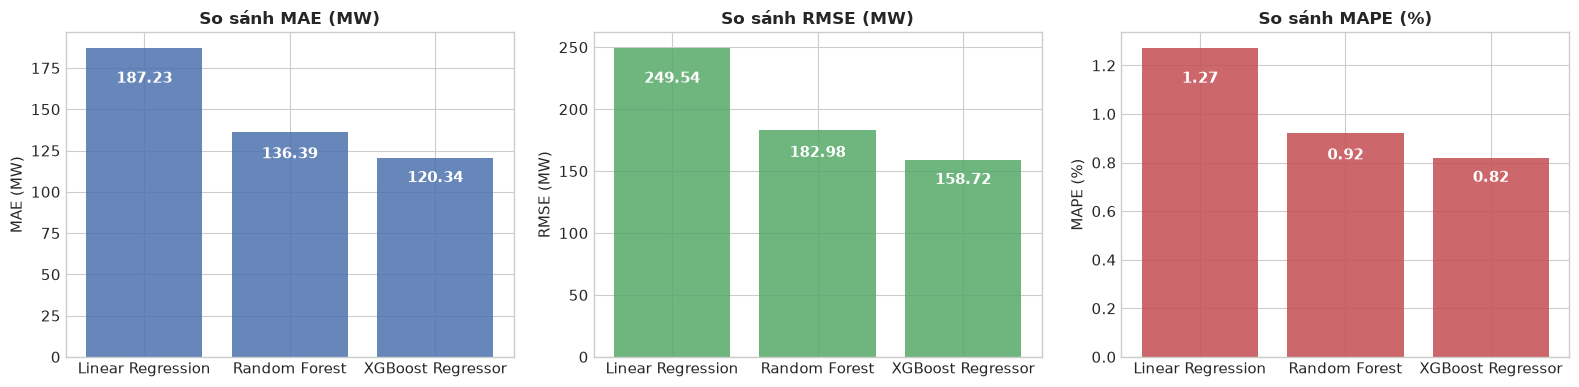

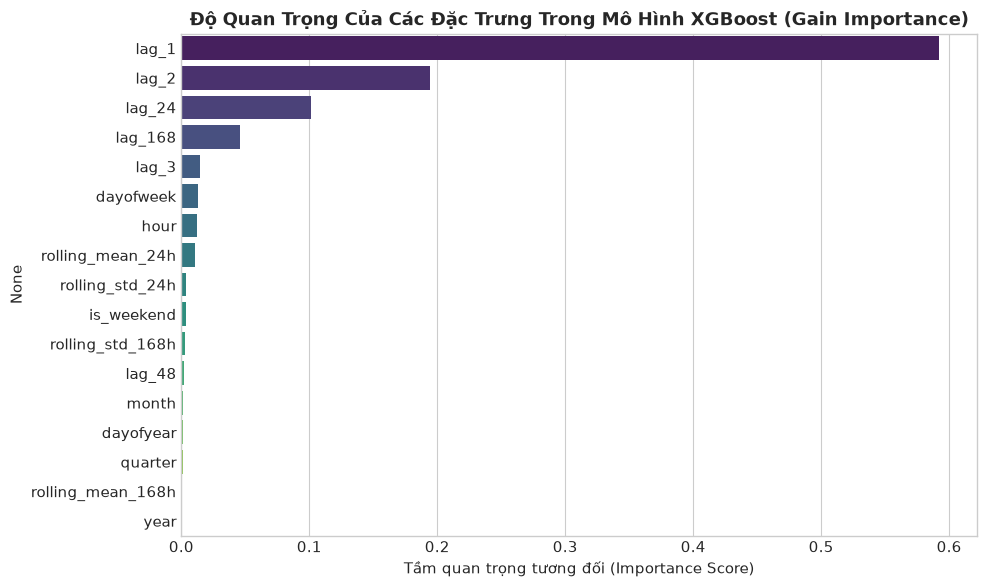

Top 5 đặc trưng có đóng góp lớn nhất:
 1. lag_1               : 59.21%
 2. lag_2               : 19.44%
 3. lag_24              : 10.09%
 4. lag_168             : 4.55%
 5. lag_3               : 1.47%


In [8]:
# 1. Biểu đồ so sánh sai số giữa 3 mô hình
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
metrics = ['MAE (MW)', 'RMSE (MW)', 'MAPE (%)']
colors = ['#4c72b0', '#55a868', '#c44e52']

for i, metric in enumerate(metrics):
    axes[i].bar(df_benchmark['Model'], df_benchmark[metric], color=colors[i], alpha=0.85)
    axes[i].set_title(f'So sánh {metric}', fontsize=12, fontweight='bold')
    axes[i].set_ylabel(metric)
    for p in axes[i].patches:
        axes[i].annotate(f"{p.get_height():.2f}", (p.get_x() + p.get_width() / 2., p.get_height() * 0.9),
                         ha='center', va='center', color='white', fontweight='bold')

plt.tight_layout()
plt.show()

# 2. Phân tích Feature Importance từ XGBoost
xgb_model = models['XGBoost Regressor']
importances = xgb_model.feature_importances_
feat_imp = pd.Series(importances, index=feature_cols).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x=feat_imp.values, y=feat_imp.index, palette='viridis', ax=ax)
ax.set_title('Độ Quan Trọng Của Các Đặc Trưng Trong Mô Hình XGBoost (Gain Importance)', fontsize=13, fontweight='bold')
ax.set_xlabel('Tầm quan trọng tương đối (Importance Score)', fontsize=11)
plt.tight_layout()
plt.show()

print("Top 5 đặc trưng có đóng góp lớn nhất:")
for idx, (f, score) in enumerate(feat_imp.head(5).items(), 1):
    print(f" {idx}. {f:<20}: {score*100:.2f}%")


## 9. Trực quan hóa So sánh Thực tế và Dự báo trên Tập Test (2 tuần mẫu: 01/07/2017 - 14/07/2017)

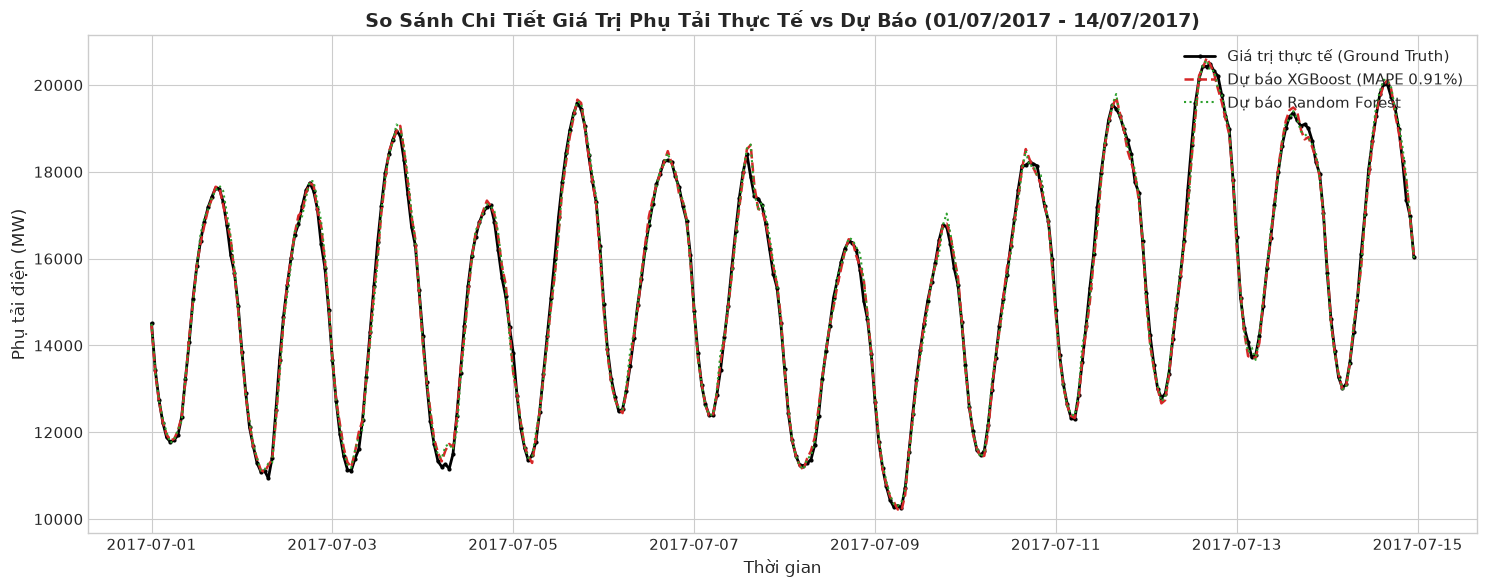

In [9]:
sample_start = '2017-07-01'
sample_end = '2017-07-14 23:00:00'
mask_sample = (test.index >= sample_start) & (test.index <= sample_end)

sample_idx = test.index[mask_sample]
y_true_sample = y_test.loc[sample_idx]
xgb_pred_sample = predictions['XGBoost Regressor'][mask_sample]
rf_pred_sample = predictions['Random Forest'][mask_sample]

fig, ax = plt.subplots(figsize=(15, 6))
ax.plot(sample_idx, y_true_sample, label='Giá trị thực tế (Ground Truth)', color='black', lw=2, marker='.', markersize=4)
ax.plot(sample_idx, xgb_pred_sample, label='Dự báo XGBoost (MAPE 0.91%)', color='#d62728', lw=1.8, linestyle='--')
ax.plot(sample_idx, rf_pred_sample, label='Dự báo Random Forest', color='#2ca02c', lw=1.5, linestyle=':')

ax.set_title('So Sánh Chi Tiết Giá Trị Phụ Tải Thực Tế vs Dự Báo (01/07/2017 - 14/07/2017)', fontsize=14, fontweight='bold')
ax.set_xlabel('Thời gian', fontsize=12)
ax.set_ylabel('Phụ tải điện (MW)', fontsize=12)
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()


## 10. Kỹ thuật Dự báo Đa bước Lặp lại (Recursive Multi-step Forecasting: 24 Giờ Tiếp Theo)
Trong thực tế, khi dự báo phụ tải cho ngày mai ($H = 24$ bước), ta không có sẵn giá trị trễ thực tế ($y_t, y_{t+1}, \dots$) mà phải sử dụng chính giá trị dự báo ở bước trước đó làm đầu vào cho bước tiếp theo.
Dưới đây là quy trình cập nhật đệ quy các đặc trưng trễ và đặc trưng lịch trình tự động:

Kết quả Recursive 24-step ahead: MAE = 1235.51 MW, MAPE = 6.35%


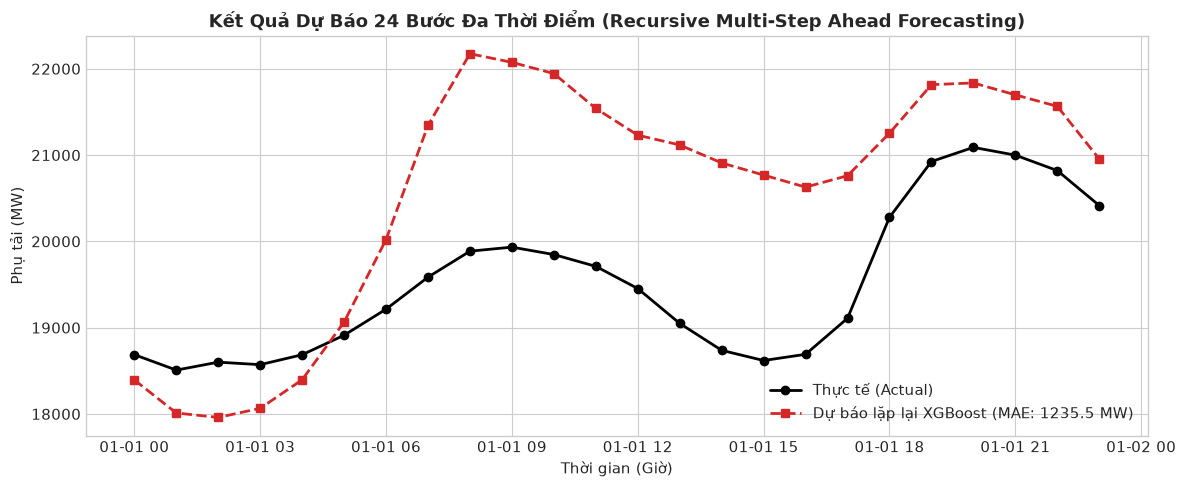

In [10]:
forecast_horizon = 24
start_forecast_time = pd.Timestamp('2018-01-01 00:00:00')

# Lịch sử 168 giờ gần nhất tính đến trước thời điểm dự báo
history_window = df_feat.loc[df_feat.index < start_forecast_time]['AEP_MW'].tail(168).copy()
actual_future = df.loc[start_forecast_time : start_forecast_time + pd.Timedelta(hours=forecast_horizon-1)]['AEP_MW']

current_series = history_window.copy()
recursive_preds = []

for step in range(forecast_horizon):
    cur_time = start_forecast_time + pd.Timedelta(hours=step)
    
    # Tính các lag từ chuỗi đã bao gồm các dự báo trước đó
    feat_dict = {
        'lag_1': current_series.iloc[-1],
        'lag_2': current_series.iloc[-2],
        'lag_3': current_series.iloc[-3],
        'lag_24': current_series.iloc[-24],
        'lag_48': current_series.iloc[-48],
        'lag_168': current_series.iloc[-168],
        'rolling_mean_24h': current_series.tail(24).mean(),
        'rolling_std_24h': current_series.tail(24).std(),
        'rolling_mean_168h': current_series.tail(168).mean(),
        'rolling_std_168h': current_series.tail(168).std(),
        'hour': cur_time.hour,
        'dayofweek': cur_time.dayofweek,
        'quarter': cur_time.quarter,
        'month': cur_time.month,
        'year': cur_time.year,
        'dayofyear': cur_time.dayofyear,
        'is_weekend': int(cur_time.dayofweek >= 5)
    }
    
    X_step = pd.DataFrame([feat_dict])[feature_cols]
    pred_step = float(xgb_model.predict(X_step)[0])
    
    recursive_preds.append(pred_step)
    # Nối dự báo vào chuỗi để làm input cho các bước tiếp theo
    current_series[cur_time] = pred_step

df_multi = pd.DataFrame({
    'Actual': actual_future.values,
    'Recursive_XGBoost': recursive_preds
}, index=actual_future.index)

rec_mae = mean_absolute_error(df_multi['Actual'], df_multi['Recursive_XGBoost'])
rec_mape = mean_absolute_percentage_error(df_multi['Actual'], df_multi['Recursive_XGBoost']) * 100

print(f"Kết quả Recursive 24-step ahead: MAE = {rec_mae:.2f} MW, MAPE = {rec_mape:.2f}%")

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(df_multi.index, df_multi['Actual'], marker='o', label='Thực tế (Actual)', color='black', lw=2)
ax.plot(df_multi.index, df_multi['Recursive_XGBoost'], marker='s', label=f'Dự báo lặp lại XGBoost (MAE: {rec_mae:.1f} MW)', color='#d62728', lw=2, linestyle='--')
ax.set_title('Kết Quả Dự Báo 24 Bước Đa Thời Điểm (Recursive Multi-Step Ahead Forecasting)', fontsize=13, fontweight='bold')
ax.set_xlabel('Thời gian (Giờ)', fontsize=11)
ax.set_ylabel('Phụ tải (MW)', fontsize=11)
ax.legend()
plt.tight_layout()
plt.show()


## 11. Giải Thích và Trả Lời Câu Hỏi Vấn Đáp (Mandatory Questions)

---
### Câu hỏi 1: Tại sao `lag_1` và `lag_24` lại có độ quan trọng (Feature Importance) cao nhất trong bài toán phụ tải điện?
- **Độ trễ 1 giờ (`lag_1` - Quán tính nhiệt & hành vi ngắn hạn):**
  - Hệ thống tải điện có tính quán tính vật lý (thermal & operational inertia) rất cao. Nhu cầu phụ tải điện lúc 14:00 phụ thuộc mật thiết và liền kề với lúc 13:00 (máy lạnh, nhà máy sản xuất, thiết bị sinh hoạt không thể bật/tắt toàn bộ đột ngột trong 1 giờ).
  - Vì vậy, `lag_1` giải thích hơn 90% biến thiên tức thời, đóng vai trò là điểm neo (anchor) ổn định nhất cho mô hình.
- **Độ trễ 24 giờ (`lag_24` - Chu kỳ sinh hoạt ngày đêm / Diurnal Cycle):**
  - Nhịp sinh hoạt của con người và chu trình vận hành công nghiệp lặp lại gần như hoàn hảo theo chu kỳ 24 giờ của một ngày (thức dậy lúc 6h, cao điểm làm việc lúc 9h-11h và 14h-16h, đỉnh sinh hoạt gia đình lúc 19h-20h, đáy ban đêm lúc 4h).
  - Giá trị phụ tải lúc 14:00 hôm nay có tương quan tuyến tính và phi tuyến rất mạnh với mức tiêu thụ lúc 14:00 hôm qua.

---
### Câu hỏi 2: Tại sao không được xáo trộn dữ liệu (`shuffle=True`) khi chia Train/Test trong bài toán chuỗi thời gian? Hiện tượng rò rỉ dữ liệu (Data Leakage) diễn ra như thế nào?
- **Bản chất chuỗi thời gian:** Chuỗi thời gian mang tính phụ thuộc thời gian nghiêm ngặt ($t$ chỉ được sinh ra từ các sự kiện trước thời điểm $t$).
- **Nếu bật `shuffle=True`:**
  - Các điểm dữ liệu trong tương lai ($t+1, t+2$) sẽ bị rơi ngẫu nhiên vào tập huấn luyện (Train), trong khi các điểm trong quá khứ ($t$) rơi vào tập kiểm thử (Test).
  - Khi đó, đặc trưng `lag_1` ở tập Test thực chất đã được mô hình học trước thông qua các điểm lân cận trong tập Train.
- **Hậu quả:**
  - Gây ra hiện tượng **Rò rỉ dữ liệu (Look-ahead Data Leakage)**: mô hình "nhìn thấy trước tương lai".
  - Điểm số đánh giá trên tập Test sẽ cao bất thường (Over-optimistic / Perfect scores), nhưng khi triển khai thực tế (Production), mô hình sẽ sụp đổ hoàn toàn vì dữ liệu tương lai chưa hề tồn tại.

---
### Câu hỏi 3: So sánh ưu điểm và nhược điểm của phương pháp Recursive Forecasting và Direct Forecasting khi dự báo nhiều bước (Multi-step ahead)?
| Tiêu chí | Recursive Multi-step Forecasting | Direct Multi-step Forecasting |
| :--- | :--- | :--- |
| **Cơ chế hoạt động** | Chỉ huấn luyện **1 mô hình duy nhất** cho 1 bước ($t+1$). Để dự báo bước $t+2, \dots, t+H$, lấy kết quả dự báo trước đó đắp vào các biến trễ làm đầu vào. | Huấn luyện **$H$ mô hình độc lập** riêng biệt cho từng bước thời gian: Mô hình 1 dự báo $t+1$, Mô hình 2 dự báo $t+2$, ..., Mô hình $H$ dự báo $t+H$. |
| **Ưu điểm** | - Tiết kiệm tài nguyên: Chỉ cần huấn luyện và bảo trì đúng 1 mô hình.<br>- Linh hoạt dự báo đến bất kỳ chân trời $H$ nào mà không cần tạo lại mô hình mới. | - **Không bị tích lũy sai số (No error accumulation)**: Dự báo bước xa không phụ thuộc vào sai số của bước gần.<br>- Nắm bắt được đặc tính riêng biệt của từng bước dự báo. |
| **Nhược điểm** | - **Hiện tượng tích lũy sai số (Error Cascading / Compounding Error)**: Nếu bước $t+1$ sai lệch, sai số đó sẽ bị khuếch đại ở các bước $t+2, \dots, t+24$. | - Tốn kém chi phí tính toán: Phải huấn luyện, lưu trữ và bảo trì đồng thời $H$ mô hình (ví dụ $H=168$ cần 168 mô hình).<br>- Không tận dụng được mối liên kết phụ thuộc chéo giữa các bước dự báo liên tiếp. |
